# 7. Differentiable Explanation: Back-Propagating Distances to Critical Structures & Robots

**What you will learn:**
1. Why $\mathrm{SW}_1$ **splits additively** across matched diagram points and their birth/death vertices — placing `100%` of the distance onto critical structures (extrema & saddles) with a physical meaning.
2. Exact numerical verification (`~1e-7` float32 tolerance) of the end-to-end differentiable PyTorch pipeline `positions x_i(t) -> velocities -> closed-form fields -> diagrams -> SW_1`.
3. Contrast between **Extended Persistence** (`42%` concentrated on the two counter-rotating centers of $\psi_\sigma$, half the mean map in `14%` of the arena) vs **Quantile Value Distributions** (`92%` scattered on arbitrary ordinary points).
4. Noise stability (`2 mm` positional jitter) and general trends across all **10 mission pairs** (`attribution_pairs.pkl`).

In [1]:
import pickle, sys
from pathlib import Path
from IPython.display import Image, display
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path[:0] = [str(ROOT / "analysis"), str(ROOT / "src"), str(ROOT)]

import figlib as L
import make_figures as M
L.style()

PAPER = ROOT / "results" / "epuck" / "paper"
load = lambda p: pickle.load(open(p, "rb"))

## 1. Verification Against Stored Pipeline & Critical-Structure Decomposition

Load `attribution.pkl` (comparing D-Gate run `74` vs Foraging run `580` on vorticity potential $\psi_{\sigma_3}$) and inspect the gradient checks and top contributing critical points.

In [2]:
A = load(PAPER / "attribution.pkl")
print(f"Pair analyzed: {A['missions'][0]} (run {A['run_A'][1]}) vs {A['missions'][1]} (run {A['run_B'][1]}) | field {A['field']} at sigma_{A['scale'] + 1}\n")
print("Pipeline match checks (PyTorch float64 vs stored float32 pipeline):")
for k, v in A["check"].items():
    print(f"  {k:40s} : {v}")

print("\nSeed attribution breakdown:")
for summary in ("persistence", "values"):
    sh = A[f"{summary}_shares_A"]
    print(f"  {summary:12s} | SW1={A[f'{summary}_distance']:.5f} | active seeds={sh['n']:3d}/{len(A[f'{summary}_share_A'])} "
          f"| critical={100*sh['critical']:5.1f}% | extrema={100*sh['extrema']:5.1f}%")

names = ["Ord0", "Ord1", "Rel1", "Rel2", "Ext0", "Ext1"]
print("\nTop 5 critical pairs on D-Gate exemplar:")
for p in A["points_A"][:5]:
    print(f"  {names[p['diagram']]:4s} ({p['birth']:+.4f}, {p['death']:+.4f})  {p['birth_type']:>6s} -> {p['death_type']:<6s}  share={p['share'] / A['persistence_distance']:.3f}")

Pair analyzed: D-Gate (run 74) vs Foraging (run 580) | field psi at sigma_3

Pipeline match checks (PyTorch float64 vs stored float32 pipeline):
  field_A_vs_stored                        : 9.715648426076585e-08
  field_A_positions_vs_stored              : 1.0101154237511063e-07
  field_B_vs_stored                        : 8.868866448507355e-08
  field_B_positions_vs_stored              : 8.915088946861064e-08
  diagrams_A_vs_stored                     : 1.0408340855860843e-17
  diagrams_A_sizes_equal                   : True
  value_match_A                            : 1.3877787807814457e-17
  pairing_A_unchanged                      : True
  diagrams_B_vs_stored                     : 6.938893903907228e-18
  diagrams_B_sizes_equal                   : True
  value_match_B                            : 1.0408340855860843e-17
  pairing_B_unchanged                      : True
  persistence_distance_vs_stored           : 6.94966562834374e-16
  value_distance_vs_stored                 : 1.56

## 2. Spatial Concentration: Critical Centers vs Ordinary Quantile Points

Extended persistence anchors every bit of weight on maxima, minima, and saddles (here the twin clockwise/counterclockwise traffic vortices at the corridor mouth). Carrying shares back via $\partial\psi_\sigma / \partial \mathbf{x}_i(t)$ pinpoints *when and where* robots turned to sustain those vortices.

saved /home/ndinga/Documents/paper_topological_kinematics/figures/fig_attribution.pdf


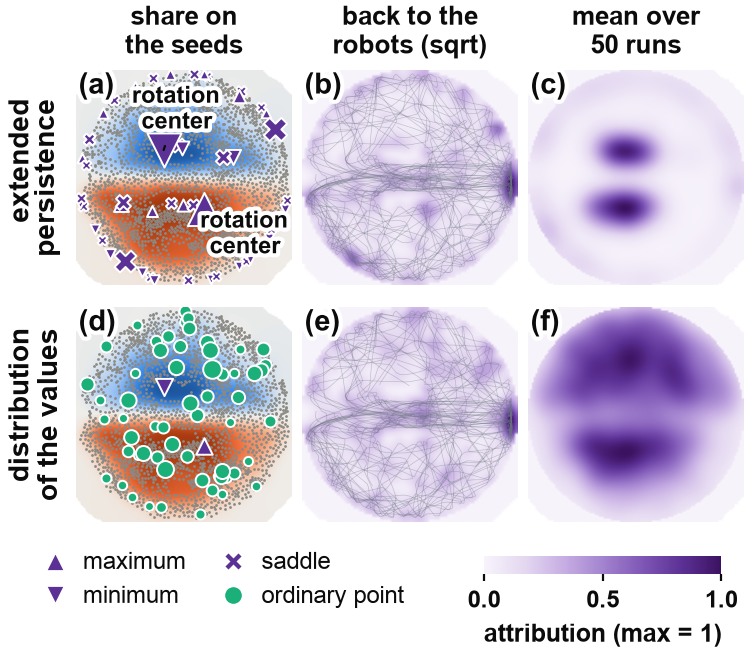

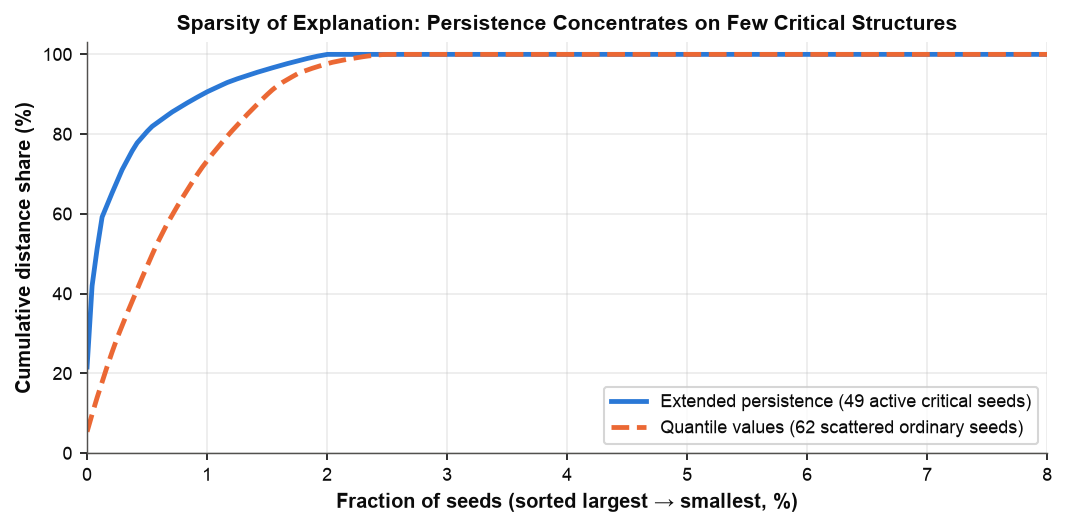

In [3]:
M.fig_attribution()
display(Image(filename=str(ROOT / "figures/fig_attribution.png"), width=860))

# Plot cumulative Pareto concentration curve of seed weights (persistence vs values)
sp_p = np.sort(np.abs(np.asarray(A["persistence_share_A"], float)))[::-1]
sp_v = np.sort(np.abs(np.asarray(A["values_share_A"], float)))[::-1]
cp = np.cumsum(sp_p) / max(sp_p.sum(), 1e-12)
cv = np.cumsum(sp_v) / max(sp_v.sum(), 1e-12)
x_pct = np.linspace(0, 100, len(sp_p))

fig, ax = plt.subplots(figsize=(7.2, 3.6))
ax.plot(x_pct, 100 * cp, lw=2.3, color=L.MCOL[0], label=f"Extended persistence ({A['persistence_shares_A']['n']} active critical seeds)")
ax.plot(x_pct, 100 * cv, lw=2.3, ls="--", color=L.MCOL[1], label=f"Quantile values ({A['values_shares_A']['n']} scattered ordinary seeds)")
ax.set_xlim(0, 8); ax.set_ylim(0, 103)
ax.set_xlabel("Fraction of seeds (sorted largest → smallest, %)"); ax.set_ylabel("Cumulative distance share (%)")
ax.set_title("Sparsity of Explanation: Persistence Concentrates on Few Critical Structures", fontweight="bold")
ax.legend(fontsize=8.5, loc="lower right"); ax.grid(alpha=0.25)
plt.tight_layout(); plt.show()

## 3. Noise Stability & All 10 Mission Pairs (`attribution_pairs.pkl`)

Let's visualize both:
1. How much of the seed split survives small positional jitter (`1..5 mm`) on **persistence vs quantiles**;
2. The top-2 extrema share and `2 mm` stability across all **10 mission pairs** (`rho`, `K`, `phi`, `psi`, `J` chosen per pair).

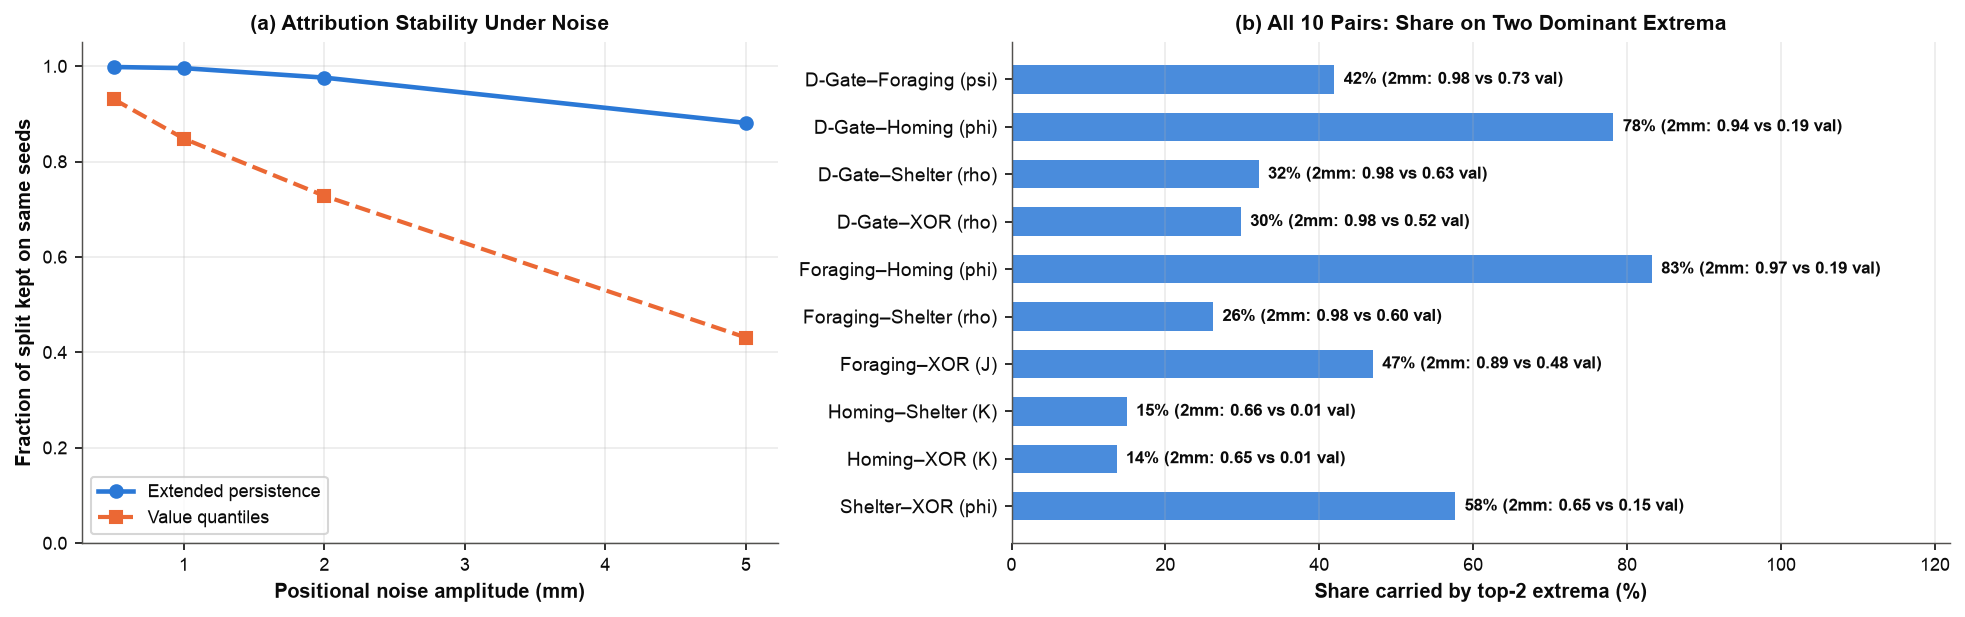

In [4]:
AP = load(PAPER / "attribution_pairs.pkl")

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(13.2, 4.2), gridspec_kw={"width_ratios": [1.0, 1.35]})

# Panel 0: Perturbation stability curve on D-Gate vs Foraging
eps_mm = [1000 * float(e) for e in A["stability"]]
pers_s = [A["stability"][e]["persistence_same"] for e in A["stability"]]
vals_s = [A["stability"][e]["values_same"] for e in A["stability"]]
ax0.plot(eps_mm, pers_s, marker="o", lw=2.2, color=L.MCOL[0], label="Extended persistence")
ax0.plot(eps_mm, vals_s, marker="s", lw=2.0, ls="--", color=L.MCOL[1], label="Value quantiles")
ax0.set_xlabel("Positional noise amplitude (mm)"); ax0.set_ylabel("Fraction of split kept on same seeds")
ax0.set_ylim(0, 1.05); ax0.set_title("(a) Attribution Stability Under Noise", fontweight="bold")
ax0.legend(fontsize=8.5); ax0.grid(alpha=0.25)

# Panel 1: All 10 mission pairs share & stability
pair_labels, shares, stab2_p, stab2_v = [], [], [], []
for (i, j), info in sorted(AP.items()):
    pair_labels.append(f"{L.MSHORT[i]}–{L.MSHORT[j]} ({info['field']})")
    shares.append(100 * info["top2_share"])
    sp, sv = info["stab2"]
    stab2_p.append(sp); stab2_v.append(sv)
y_idx = np.arange(len(pair_labels))[::-1]
ax1.barh(y_idx, shares, height=0.6, color=L.MCOL[0], alpha=0.85)
for yy, sh, sp, sv in zip(y_idx, shares, stab2_p, stab2_v):
    ax1.text(sh + 1.2, yy, f"{sh:.0f}% (2mm: {sp:.2f} vs {sv:.2f} val)", va="center", fontsize=8.2, fontweight="bold")
ax1.set_yticks(y_idx); ax1.set_yticklabels(pair_labels, fontsize=9)
ax1.set_xlim(0, 122); ax1.set_xlabel("Share carried by top-2 extrema (%)")
ax1.set_title("(b) All 10 Pairs: Share on Two Dominant Extrema", fontweight="bold")
ax1.grid(axis="x", alpha=0.25)
plt.tight_layout(); plt.show()